[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vvvvvivekkk/AI-Engineer/blob/main/04-machine-learning/notebooks/03-trees-forests-kmeans.ipynb)

# 04-03 · Decision trees, random forests and k-means

**Goal:** meet three new models.
- **Decision tree** — a flowchart of yes/no questions.
- **Random forest** — many trees voting together (an **ensemble**).
- **k-means** — an **unsupervised** method that finds groups without labels.

Everything runs in seconds.

## Step 1 · Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine, load_iris, make_blobs
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, adjusted_rand_score

## Step 2 · A small decision tree on the wine data

178 wines, 13 chemical measurements, 3 grape types. We limit the tree to `max_depth=2` (at most two questions in a row) so we can read it. `max_depth` is a **hyperparameter** — a setting we choose, not something the model learns.

In [2]:
wine = load_wine(as_frame=True)
X, y = wine.data, wine.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)

tree = DecisionTreeClassifier(max_depth=2, random_state=0)
tree.fit(X_train, y_train)
print("train accuracy:", round(tree.score(X_train, y_train), 3))
print("test accuracy: ", round(tree.score(X_test, y_test), 3))

train accuracy: 0.927
test accuracy:  0.852


`export_text` prints the tree as plain text: each line is a question, and each leaf says which class it predicts. Notice that a tree needs **no scaling** — it only compares a feature with a cut-off.

In [3]:
print(export_text(tree, feature_names=list(X.columns)))

|--- proline <= 765.00
|   |--- flavanoids <= 1.40
|   |   |--- class: 2
|   |--- flavanoids >  1.40
|   |   |--- class: 1
|--- proline >  765.00
|   |--- flavanoids <= 2.17
|   |   |--- class: 2
|   |--- flavanoids >  2.17
|   |   |--- class: 0



The same tree as a picture. Each box shows the question, the **gini** impurity (0 = the box contains only one class; higher = more mixed), how many training samples reached it, and the class counts.

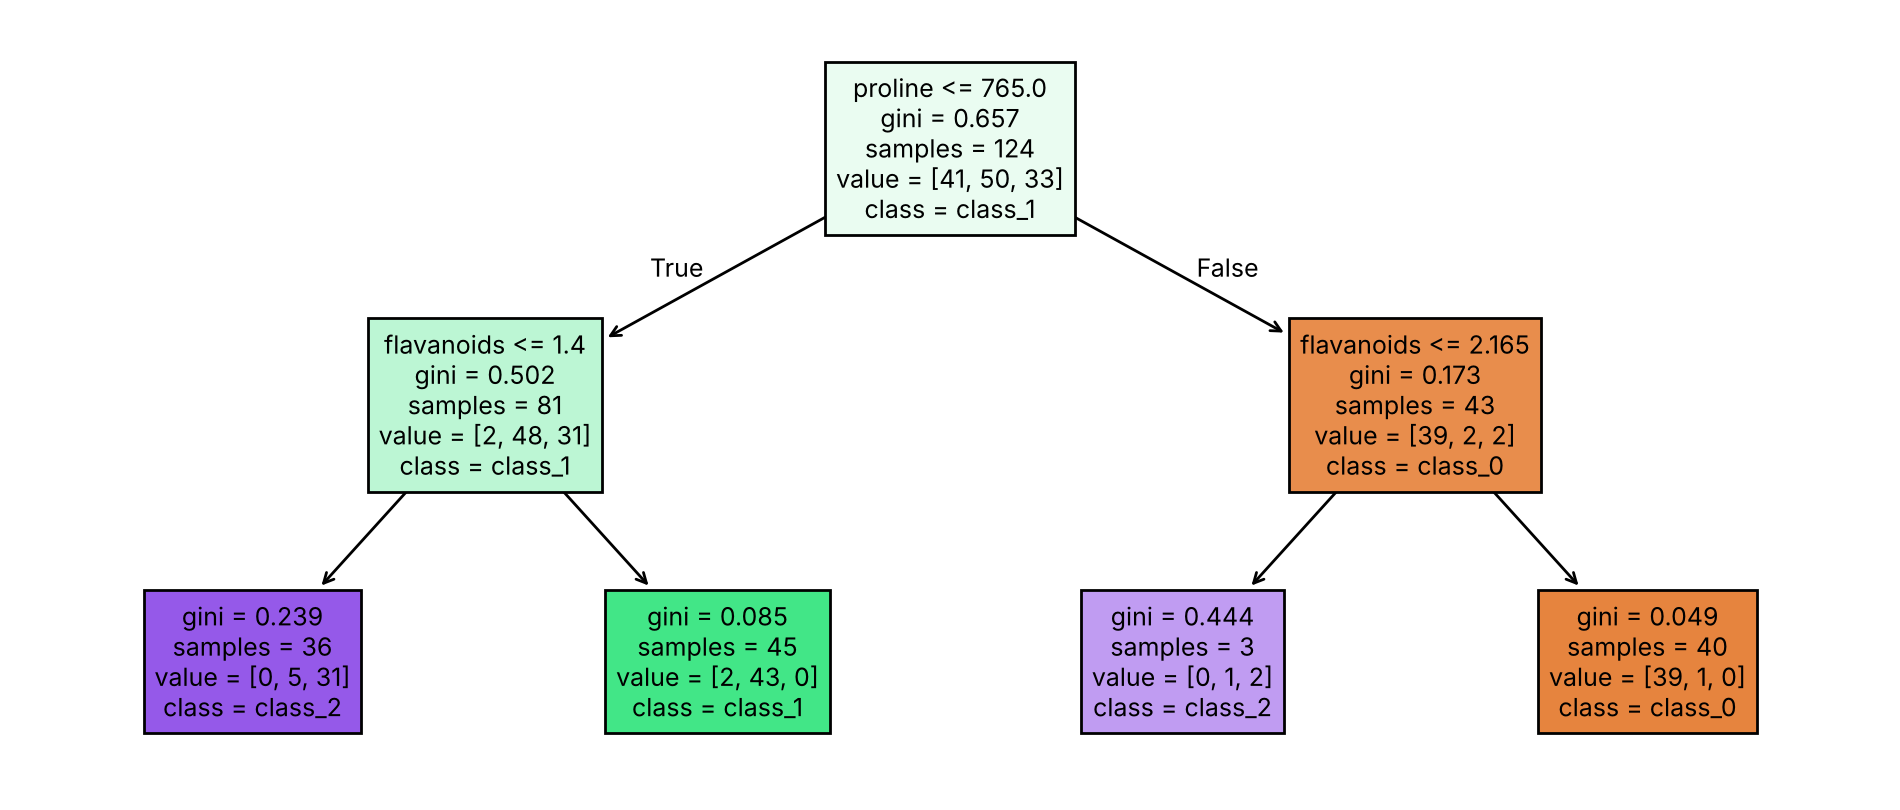

In [4]:
plt.figure(figsize=(12, 5))
plot_tree(tree, feature_names=X.columns, class_names=wine.target_names, filled=True, fontsize=9)
plt.show()

## Step 3 · What happens when we let the tree grow?

We train trees of increasing depth and compare training and test accuracy. When training accuracy hits 1.0 but test accuracy does not improve, the tree is memorising — **overfitting**.

In [5]:
for depth in [1, 2, 3, 5, None]:
    t = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(X_train, y_train)
    print(f"max_depth={str(depth):4s}  train={t.score(X_train, y_train):.3f}  "
          f"test={t.score(X_test, y_test):.3f}  leaves={t.get_n_leaves()}")

max_depth=1     train=0.702  test=0.667  leaves=2
max_depth=2     train=0.927  test=0.852  leaves=4
max_depth=3     train=0.984  test=0.963  leaves=8
max_depth=5     train=1.000  test=0.944  leaves=9
max_depth=None  train=1.000  test=0.944  leaves=9


## Step 4 · Random forest: many trees vote

`n_estimators=200` grows 200 trees, each on a random sample of rows and features. `n_jobs=1` uses one CPU core (polite on shared machines; use `-1` on your own laptop for all cores).

In [6]:
forest = RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=1)
forest.fit(X_train, y_train)
print("forest train accuracy:", round(forest.score(X_train, y_train), 3))
print("forest test accuracy: ", round(forest.score(X_test, y_test), 3))

forest train accuracy: 1.0
forest test accuracy:  1.0


**Feature importances** tell us how much each feature helped the forest's decisions (they add up to 1). This is a quick way to explain a model to a non-technical audience.

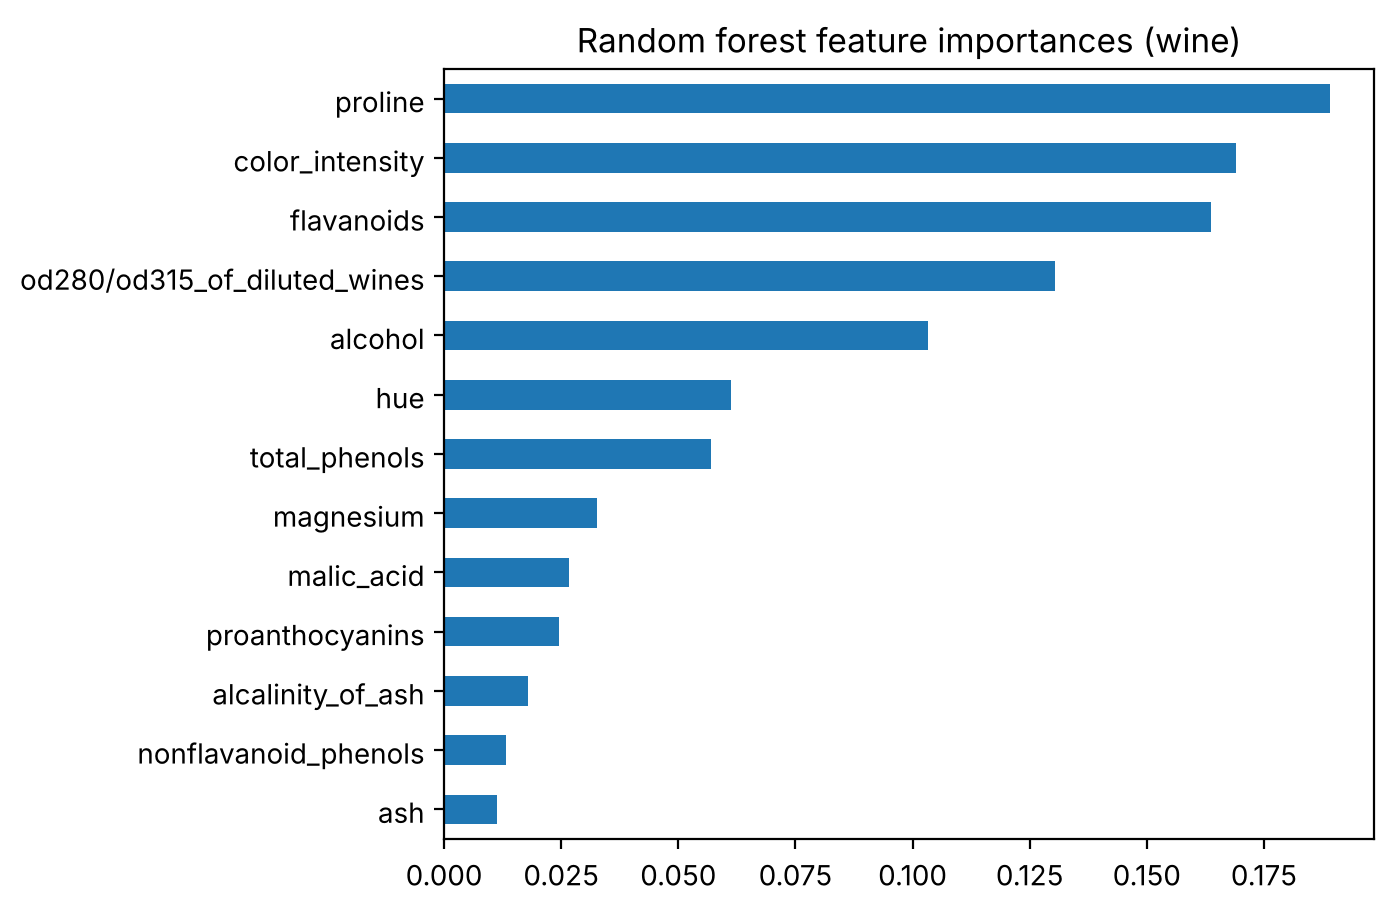

In [7]:
imp = pd.Series(forest.feature_importances_, index=X.columns).sort_values()
imp.plot.barh(figsize=(6, 5), title="Random forest feature importances (wine)")
plt.show()

## Step 5 · k-means on synthetic blobs

Now the **unsupervised** part. `make_blobs` creates points around 3 hidden centres. We give k-means the points **without** the true groups and ask for `n_clusters=3`. `n_init=10` runs the algorithm 10 times from different random starts and keeps the best.

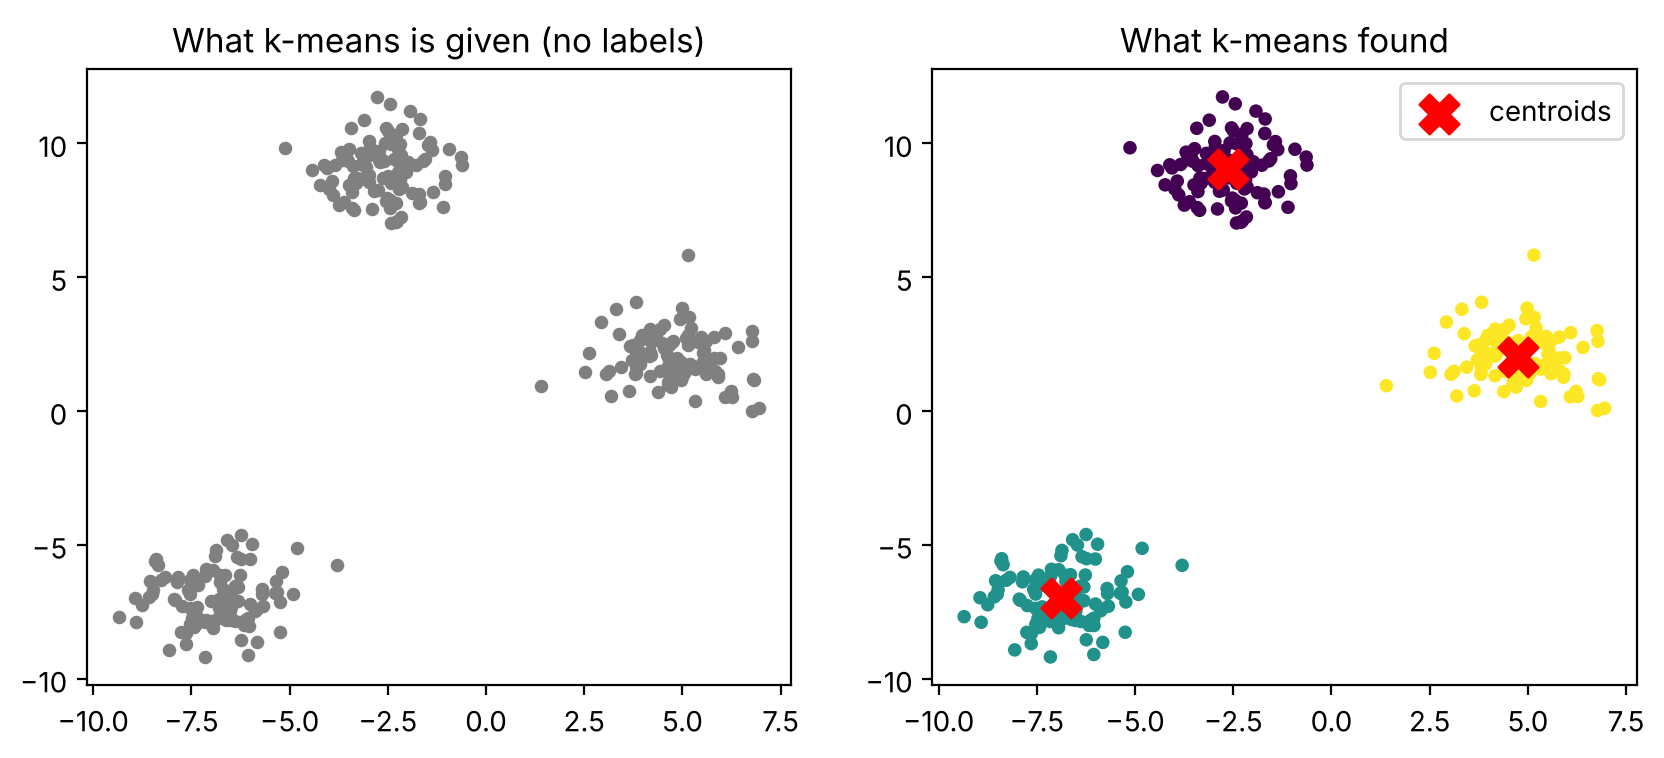

In [8]:
Xb, true_groups = make_blobs(n_samples=300, centers=3, cluster_std=1.0, random_state=42)
km = KMeans(n_clusters=3, n_init=10, random_state=42)
labels = km.fit_predict(Xb)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(Xb[:, 0], Xb[:, 1], c="grey", s=15); axes[0].set_title("What k-means is given (no labels)")
axes[1].scatter(Xb[:, 0], Xb[:, 1], c=labels, cmap="viridis", s=15)
axes[1].scatter(*km.cluster_centers_.T, c="red", marker="X", s=200, label="centroids")
axes[1].set_title("What k-means found"); axes[1].legend()
plt.show()

## Step 6 · Choosing k with the elbow plot

**Inertia** = total squared distance from each point to its centroid. More clusters always lower it, so we look for the "elbow" where the curve stops dropping steeply.

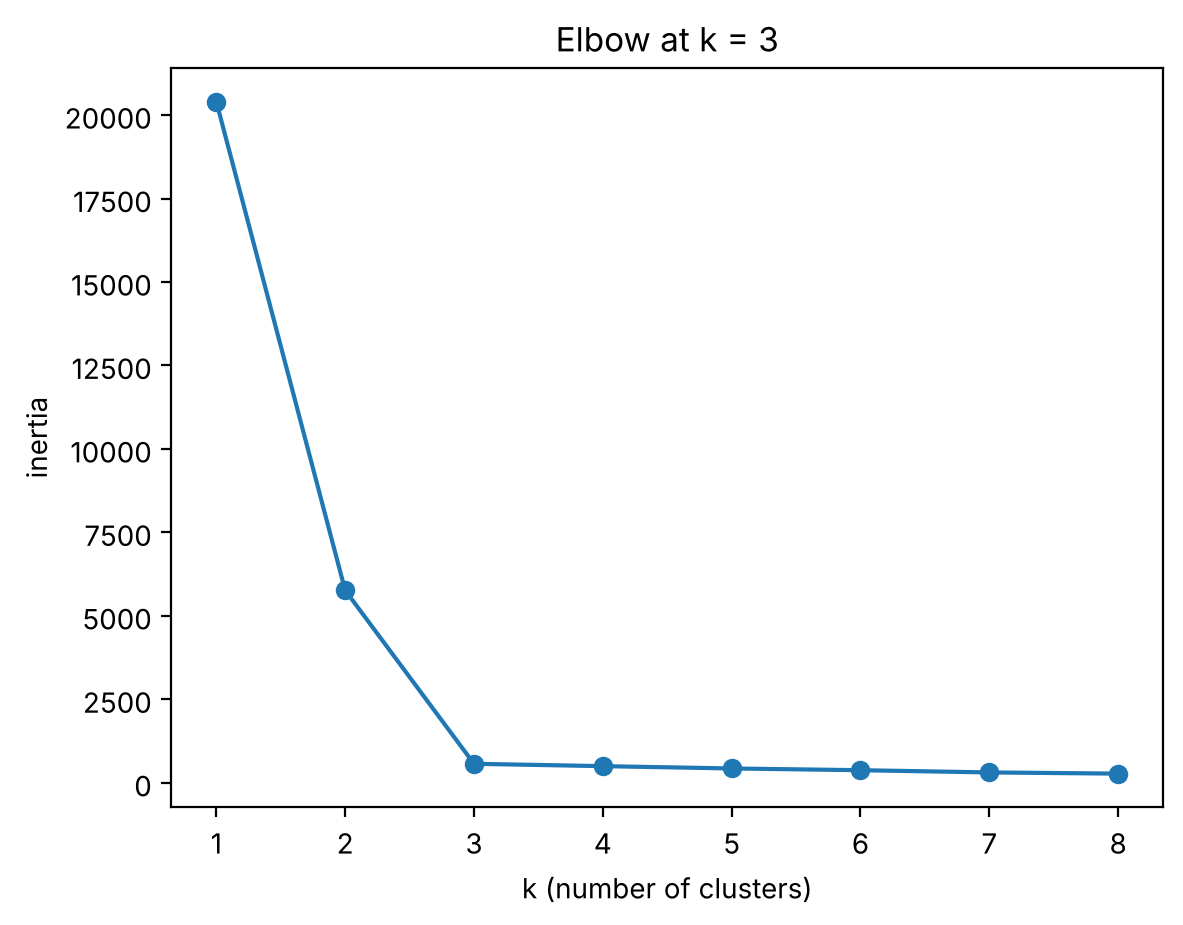

In [9]:
ks = range(1, 9)
inertias = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xb).inertia_ for k in ks]
plt.plot(ks, inertias, "o-")
plt.xlabel("k (number of clusters)"); plt.ylabel("inertia")
plt.title("Elbow at k = 3"); plt.show()

## Step 7 · k-means on real data (iris) — did it find the species?

We hide the iris species, scale the 4 measurements, and cluster into 3 groups. Cluster numbers are arbitrary (cluster "0" need not be species "0"), so we use the **adjusted Rand index (ARI)**: 1.0 = groups match the species perfectly, about 0 = random.

In [10]:
iris = load_iris()
Xi = StandardScaler().fit_transform(iris.data)
iris_labels = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(Xi)
print("ARI vs true species:", round(adjusted_rand_score(iris.target, iris_labels), 3))
print(pd.crosstab(iris.target, iris_labels, rownames=["true species"], colnames=["cluster"]))

ARI vs true species: 0.62
cluster        0   1   2
true species            
0              0  50   0
1             39   0  11
2             14   0  36


One species (setosa) is found perfectly, but the other two species get mixed up quite a lot, because their measurements overlap. That is typical: clusters are a useful *suggestion*, not ground truth. (Try it without scaling — on iris the result changes, which shows how sensitive k-means is to feature scale.)

## Recap

- Trees: readable, no scaling needed, but overfit when deep.
- Random forests: many trees vote → usually more accurate and more stable.
- k-means: groups unlabelled data; you choose k (elbow plot helps); scale features first.